In [ ]:
import os, glob, re, pickle
from functools import partial
from collections import OrderedDict
import operator as op
from cytoolz import compose

import pandas as pd
import seaborn as sns
import numpy as np
import scanpy as sc
import scanpy.external as sce
import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
sc.settings.verbosity = 3
sc.logging.print_header()
sc.set_figure_params(dpi=100, dpi_save=600)

from pyscenic.export import export2loom, add_scenic_metadata
from pyscenic.utils import load_motifs
from pyscenic.transform import df2regulons
from pyscenic.aucell import aucell
from pyscenic.binarization import binarize
from pyscenic.rss import regulon_specificity_scores
from pyscenic.plotting import plot_binarization, plot_rss

from IPython.display import HTML, display

import base64
import glob
import json
import loompy as lp
import os
import scipy
import zlib

from matplotlib import rcParams
from adjustText import adjust_text

# if AttributeError: module 'numpy' has no attribute 'object'. `np.object` was a deprecated alias for the builtin `object`, go to /home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/pyscenic/transform.py line 42-44, chang np.object to object

scanpy==1.8.2 anndata==0.7.8 umap==0.5.2 numpy==1.21.5 scipy==1.7.3 pandas==1.3.5 scikit-learn==1.0.2 statsmodels==0.13.1 python-igraph==0.9.9 pynndescent==0.5.5


In [6]:
# set a working directory
wdir = "C:/Users/hyjfo/Documents/"
os.chdir(wdir)

# path to loom file with basic filtering applied (this will be created in the "initial filtering" step below).
f_loom_path_scenic = "C:/Users/hyjfo/Documents/ACT_sub2_filtered_for_scenic.loom"

In [ ]:
# create these folders manually
AUXILLIARIES_FOLDERNAME = "C:/Users/hyjfo/Documents/auxilliaries/"
RESULTS_FOLDERNAME = "C:/Users/hyjfo/Documents/ACT_sub2/results/"    # should manually create this 'results' folder
FIGURES_FOLDERNAME = "C:/Users/hyjfo/Documents/ACT_sub2/figures/"
sc.settings.figdir = FIGURES_FOLDERNAME

In [8]:
# Auxilliary functions
BASE_URL = "http://motifcollections.aertslab.org/v10/logos/"
COLUMN_NAME_LOGO = "MotifLogo"
COLUMN_NAME_MOTIF_ID = "MotifID"
COLUMN_NAME_TARGETS = "TargetGenes"

In [9]:
def savesvg(fname: str, fig, folder: str=FIGURES_FOLDERNAME) -> None:
    """
    Save figure as vector-based SVG image format.
    """
    fig.tight_layout()
    fig.savefig(os.path.join(folder, fname), format='svg')

In [ ]:
def display_logos(df: pd.DataFrame, top_target_genes: int = 3, base_url: str = BASE_URL):
    """
    :param df:
    :param base_url:
    """
    # Make sure the original dataframe is not altered.
    df = df.copy()
    
    # Add column with URLs to sequence logo.
    def create_url(motif_id):
        return '<img src="{}{}.png" style="max-height:124px;"></img>'.format(base_url, motif_id)
    df[("Enrichment", COLUMN_NAME_LOGO)] = list(map(create_url, df.index.get_level_values(COLUMN_NAME_MOTIF_ID)))
    
    # Truncate TargetGenes.
    def truncate(col_val):
        return sorted(col_val, key=op.itemgetter(1))[:top_target_genes]
    df[("Enrichment", COLUMN_NAME_TARGETS)] = list(map(truncate, df[("Enrichment", COLUMN_NAME_TARGETS)]))
    
    MAX_COL_WIDTH = pd.get_option('display.max_colwidth')
    pd.set_option('display.max_colwidth', None)
    display(HTML(df.head().to_html(escape=False)))
    pd.set_option('display.max_colwidth', MAX_COL_WIDTH)

In [11]:
# Auxilliary data sets, put the files into coresponding folders
Mouse_TFS_FNAME = os.path.join(AUXILLIARIES_FOLDERNAME, 'mm_mgi_tfs.txt')
RANKING_DBS_FNAMES = list(map(lambda fn: os.path.join(AUXILLIARIES_FOLDERNAME, fn),
                       ['mm10__refseq-r80__10kb_up_and_down_tss.mc9nr.feather','mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr.feather']))
MOTIF_ANNOTATIONS_FNAME = os.path.join(AUXILLIARIES_FOLDERNAME, 'motifs-v9-nr.mgi-m0.001-o0.0.tbl')

In [12]:
# input resources
DATASET_ID = "ACT_sub2"
TCGA_CODE = 'mouse_COAD'

In [13]:
raw = sc.read('D:/HYJ/scRNA-seq/Apc_Cracd_KO_Tumor/ACT_raw_after_SoupX_Scrublet.h5ad')
raw

AnnData object with n_obs × n_vars = 13497 × 32285
    obs: 'predicted_doublets'
    var: 'gene_ids'

In [14]:
processed = sc.read('C:/Users/hyjfo/Documents/ACT_adata_sub2.h5ad')
processed

AnnData object with n_obs × n_vars = 2642 × 5000
    obs: 'predicted_doublets', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'MCADvsNormal', 'MCADvsNonMCAD'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'pca', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [15]:
raw.obs['leiden']= processed.obs['leiden']
adata=raw[raw.obs['leiden'].isin(['Wnt activated (Wnt6)', 'Parenchymal (F3)', 'Proliferating (Mki67)', 'Mucinous (Muc2)', 'Parenchymal (Muc3)'])]
adata

View of AnnData object with n_obs × n_vars = 2642 × 32285
    obs: 'predicted_doublets', 'leiden'
    var: 'gene_ids'

In [16]:
# create Results path
ADJACENCIES_FNAME = os.path.join(RESULTS_FOLDERNAME, '{}.adjacencies.tsv'.format(DATASET_ID))
MOTIFS_FNAME = os.path.join(RESULTS_FOLDERNAME, '{}.motifs.csv'.format(DATASET_ID))
REGULONS_DAT_FNAME = os.path.join(RESULTS_FOLDERNAME, '{}.regulons.dat'.format(DATASET_ID))
AUCELL_MTX_FNAME = os.path.join(RESULTS_FOLDERNAME, '{}.aucell.csv'.format(DATASET_ID))
BINARY_MTX_FNAME = os.path.join(RESULTS_FOLDERNAME, '{}.binary.csv'.format(DATASET_ID))
THR_FNAME = os.path.join(RESULTS_FOLDERNAME, '{}.thresholds.csv'.format(DATASET_ID))
ANNDATA_FNAME = os.path.join(RESULTS_FOLDERNAME, '{}.h5ad'.format(DATASET_ID))
LOOM_FNAME = os.path.join(RESULTS_FOLDERNAME, '{}_{}.loom'.format(TCGA_CODE, DATASET_ID))

In [17]:
# STEP 0: Preprocessing

normalizing counts per cell
    finished (0:00:00)


C:\Users\Park_Lab\anaconda3\envs\KP_py38\lib\site-packages\scanpy\preprocessing\_normalization.py:155: UserWarning: Revieved a view of an AnnData. Making a copy.
  view_to_actual(adata)


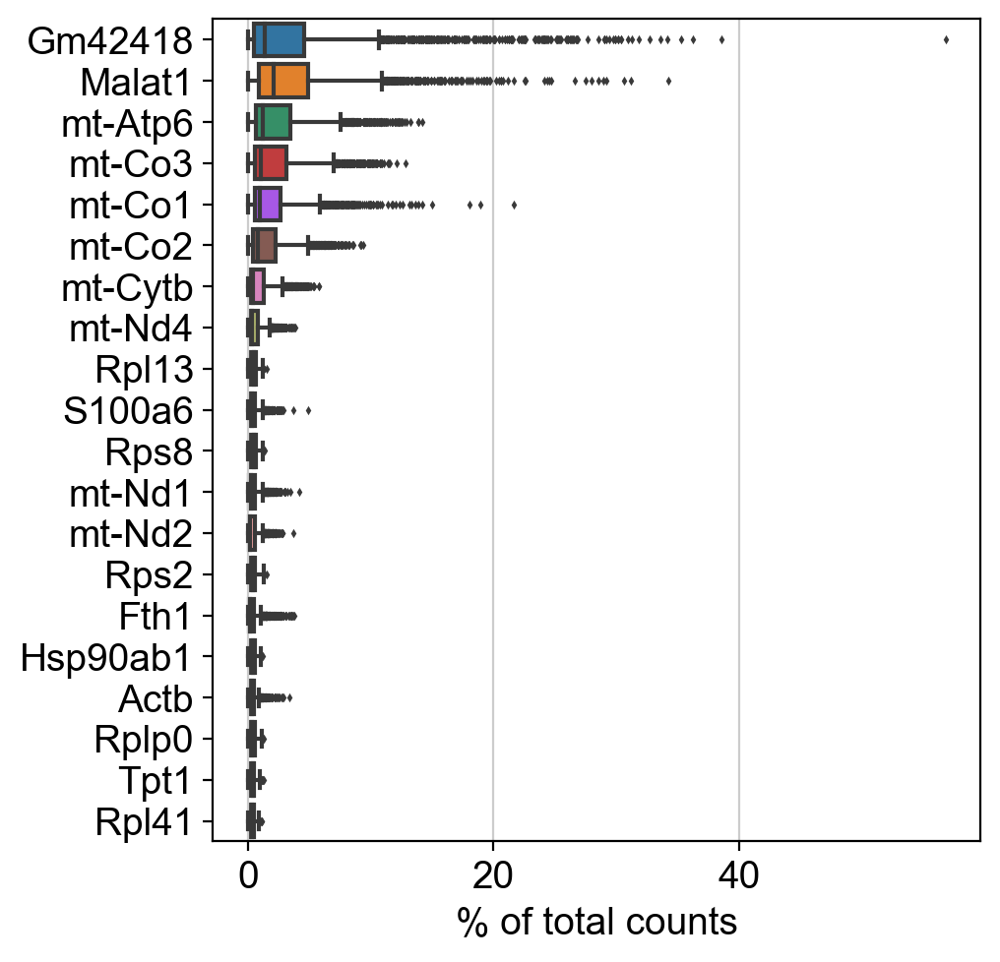

filtered out 19190 genes that are detected in less than 25 cells


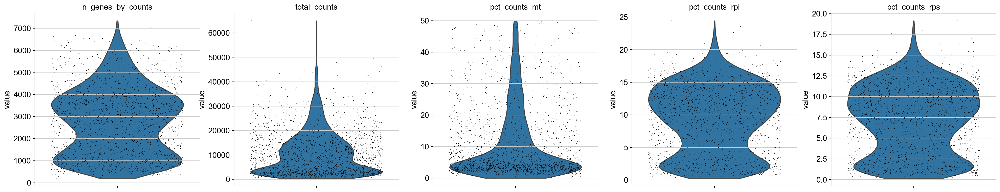

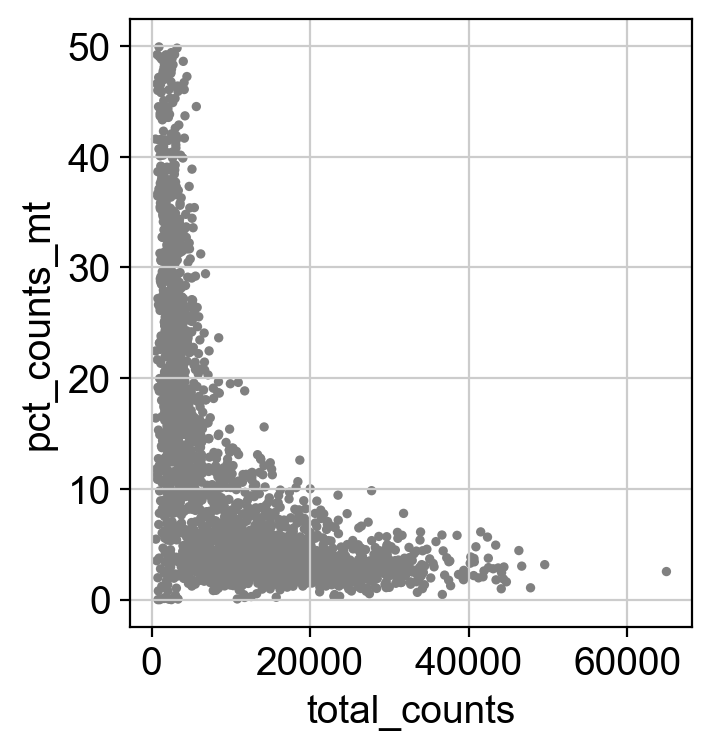

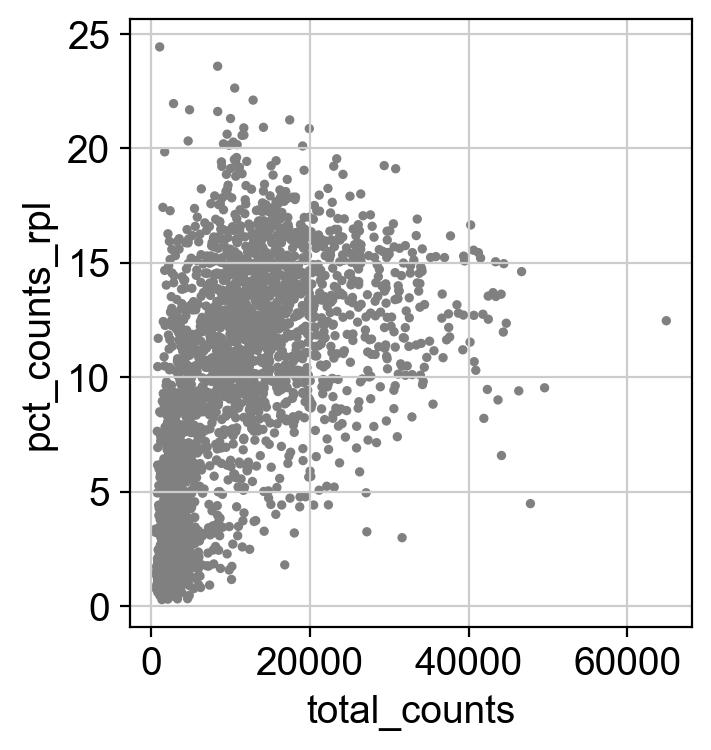

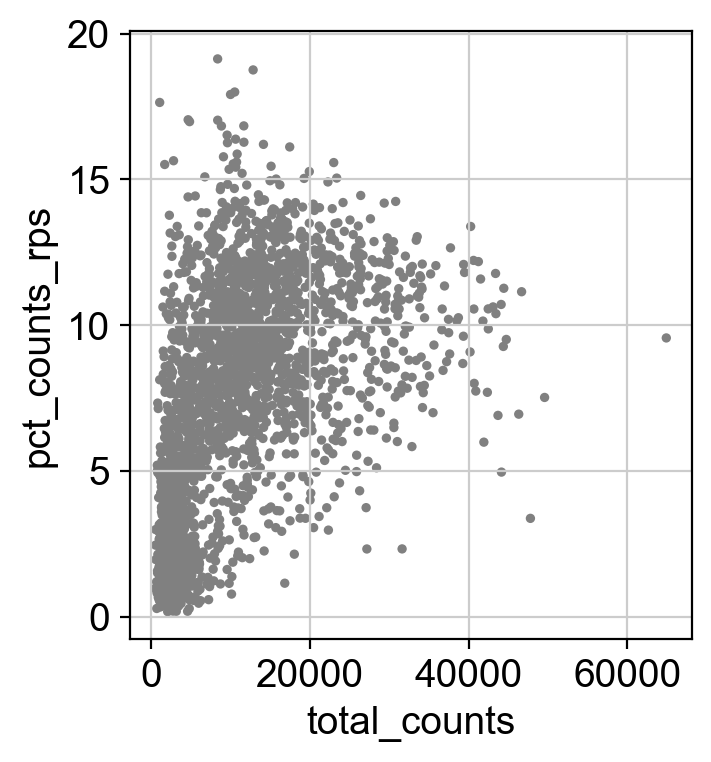

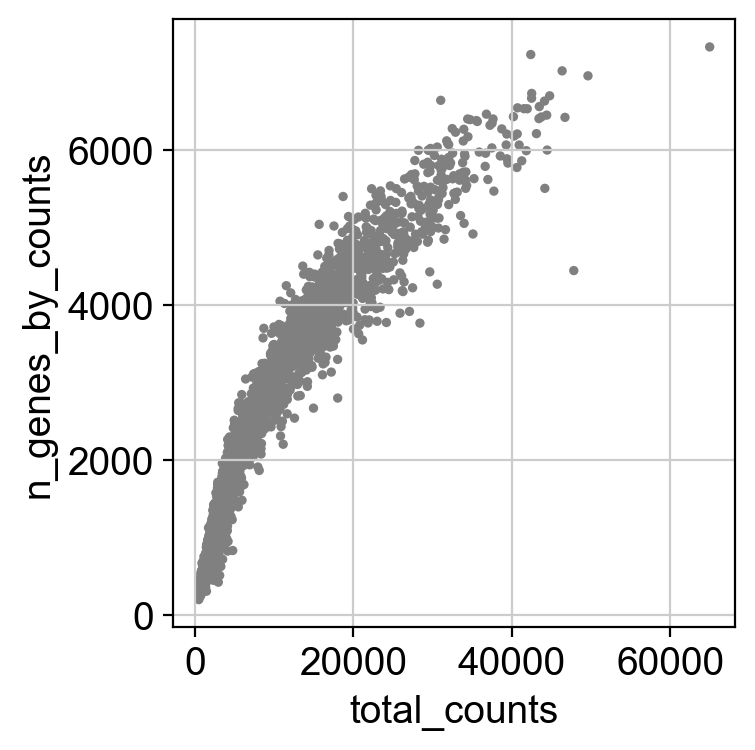

View of AnnData object with n_obs × n_vars = 2642 × 13095
    obs: 'predicted_doublets', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [18]:
sc.pl.highest_expr_genes(adata, n_top=20)
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata, min_cells=25)
adata.var['mt'] = adata.var_names.str.startswith('mt-')
adata.var['rpl'] = adata.var_names.str.startswith('Rpl')
adata.var['rps'] = adata.var_names.str.startswith('Rps')
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt','rpl','rps'], percent_top=None, log1p=False, inplace=True)
sc.pl.violin(adata, keys=['n_genes_by_counts', 'total_counts', 'pct_counts_mt','pct_counts_rpl','pct_counts_rps'], jitter=0.4, multi_panel=True)
sc.pl.scatter(adata, x='total_counts', y='pct_counts_mt')
sc.pl.scatter(adata, x='total_counts', y='pct_counts_rpl')
sc.pl.scatter(adata, x='total_counts', y='pct_counts_rps')
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts')
adata = adata[adata.obs.n_genes_by_counts < 8000, :]
adata = adata[adata.obs.pct_counts_mt < 50, :]
adata = adata[adata.obs.pct_counts_rpl < 50, :]
adata = adata[adata.obs.pct_counts_rps < 50, :]
adata

In [19]:
# Output the basic filtered expression matrix to f_loom_path_scenic
row_attrs = {"Gene": np.array(adata.var_names)}
col_attrs = {"CellID": np.array(adata.obs_names), "nGene": np.array(np.sum(adata.X.transpose()>0, axis=0)).flatten(),
             "nUMI": np.array(np.sum(adata.X.transpose(), axis=0)).flatten()}
lp.create(f_loom_path_scenic, adata.X.transpose(), row_attrs, col_attrs)
# key step, after basic filtering, save un-logtransformed data into f_loom_path_scenic for GRNBoost2

normalizing counts per cell
    finished (0:00:00)
If you pass `n_top_genes`, all cutoffs are ignored.
extracting highly variable genes


C:\Users\Park_Lab\anaconda3\envs\KP_py38\lib\site-packages\scanpy\preprocessing\_normalization.py:155: UserWarning: Revieved a view of an AnnData. Making a copy.
  view_to_actual(adata)


    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


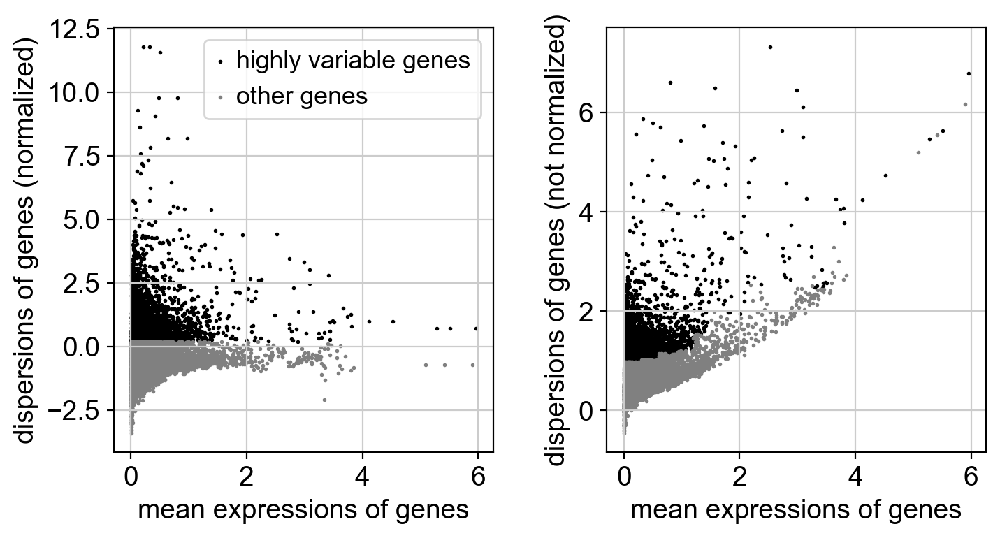

5000
regressing out ['total_counts', 'pct_counts_mt', 'pct_counts_rpl', 'pct_counts_rps']
    sparse input is densified and may lead to high memory use
    finished (0:00:11)
computing PCA
    on highly variable genes
    with n_comps=50
    finished (0:00:01)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:02)
running Leiden clustering
    finished: found 5 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:04)


In [20]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=5000)
sc.pl.highly_variable_genes(adata)
print(sum(adata.var.highly_variable))
adata.raw=adata
adata = adata[:, adata.var.highly_variable]
sc.pp.regress_out(adata, keys=['total_counts', 'pct_counts_mt','pct_counts_rpl','pct_counts_rps'], n_jobs=16)
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, svd_solver='arpack')
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=50, knn=True)
sc.tl.leiden(adata, resolution=0.4)
sc.tl.umap(adata)

In [21]:
cluster_names = ['Wnt activated (Wnt6)', 'Proliferating (Mki67)', 'Parenchymal (F3)', 'Parenchymal (Muc3)', 'Mucinous (Muc2)']
adata.rename_categories('leiden', cluster_names)

C:\Users\Park_Lab\anaconda3\envs\KP_py38\lib\site-packages\pandas\core\arrays\categorical.py:2631: FutureWarning: The `inplace` parameter in pandas.Categorical.rename_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  res = method(*args, **kwargs)


In [22]:
adata.obs['leiden'].cat.reorder_categories(['Wnt activated (Wnt6)', 'Parenchymal (F3)', 'Proliferating (Mki67)', 'Mucinous (Muc2)', 'Parenchymal (Muc3)'], inplace = True)

C:\Users\Park_Lab\AppData\Local\Temp/ipykernel_12148/1081057908.py:1: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  adata.obs['leiden'].cat.reorder_categories(['Wnt activated (Wnt6)', 'Parenchymal (F3)', 'Proliferating (Mki67)', 'Mucinous (Muc2)', 'Parenchymal (Muc3)'], inplace = True)


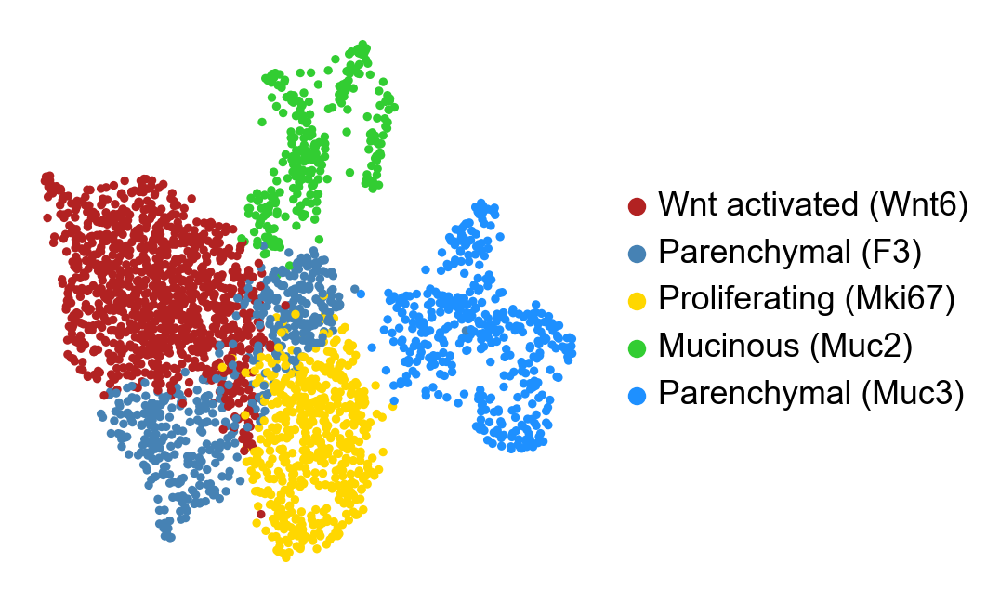

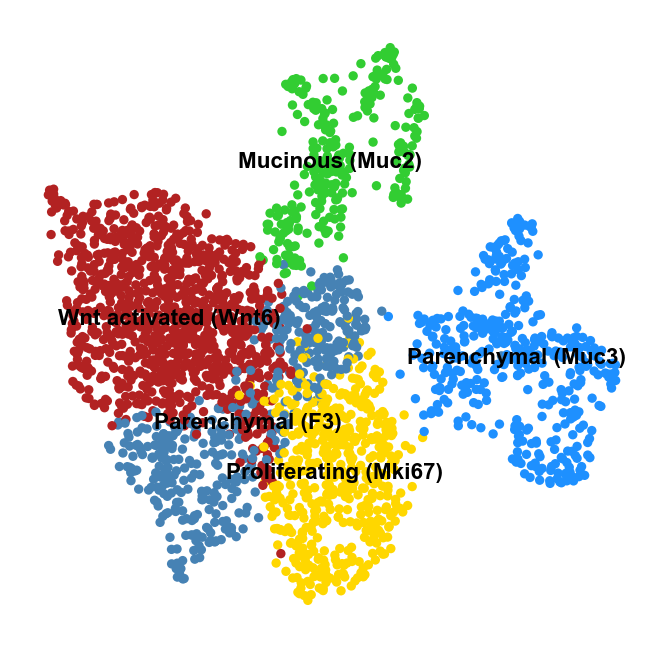

In [23]:
sc.pl.umap(adata, color=['leiden'], legend_loc='right margin', frameon=False, title='', use_raw=True,
           palette={'Wnt activated (Wnt6)': 'firebrick', 'Proliferating (Mki67)': 'gold',
                    'Parenchymal (F3)': 'steelblue', 'Parenchymal (Muc3)': 'dodgerblue',
                    'Mucinous (Muc2)': 'limegreen'}, save='2.pdf')
sc.pl.umap(adata, color=['leiden'], legend_loc='on data', frameon=False, title='', use_raw=True, legend_fontsize='xx-small')

In [24]:
# create adata.obs['pca_leiden'] to store leiden cluster names determined by pca, because later aucell based embedding will cover adata.obs['leiden']
adata.obs['pca_leiden'] = adata.obs['leiden']
adata.uns['pca_leiden_colors'] = adata.uns['leiden_colors']

In [25]:
adata    # there will generate adata.uns['pca_leiden_colors']

AnnData object with n_obs × n_vars = 2642 × 5000
    obs: 'predicted_doublets', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'pca_leiden'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'leiden', 'umap', 'leiden_colors', 'pca_leiden_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [26]:
# STEP 1: Regulatory network inference and Module generation

In [ ]:
%%time
!pyscenic grn {f_loom_path_scenic} {Mouse_TFS_FNAME} -o {ADJACENCIES_FNAME} --num_workers 16
# num_workers>16 may make memory budget error
# if TypeError: Must supply at least one delayed object, go to /home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/arboreto/core.py, comment out line 450 # all_meta_df = from_delayed(delayed_meta_dfs, meta=_META_SCHEMA). See https://github.com/aertslab/pySCENIC/issues/592#issuecomment-2567718783

preparing dask client
parsing input
creating dask graph
16 partitions
computing dask graph
not shutting down client, client was created externally
finished
Wall time: 1h 21min



2022-04-27 22:17:57,423 - pyscenic.cli.pyscenic - INFO - Loading expression matrix.

2022-04-27 22:17:57,923 - pyscenic.cli.pyscenic - INFO - Inferring regulatory networks.

2022-04-27 23:38:35,590 - pyscenic.cli.pyscenic - INFO - Writing results to file.


In [24]:
# STEP 2-3: Motif enrichment and TF-regulon prediction

In [25]:
DBS_PARAM = ' '.join(RANKING_DBS_FNAMES)

In [26]:
%%time
!pyscenic ctx {ADJACENCIES_FNAME} {DBS_PARAM} \
            --annotations_fname {MOTIF_ANNOTATIONS_FNAME} \
            --expression_mtx_fname {f_loom_path_scenic} \
            --output {MOTIFS_FNAME} \
            --num_workers 16
# The results is a list of enriched motifs for the modules


[                                        ] | 0% Completed |  0.0s
[                                        ] | 0% Completed |  0.1s
[                                        ] | 0% Completed |  0.3s
[                                        ] | 0% Completed |  0.4s
[                                        ] | 0% Completed |  0.5s
[                                        ] | 0% Completed |  0.7s
[                                        ] | 0% Completed |  0.8s
[                                        ] | 0% Completed |  0.9s
[                                        ] | 0% Completed |  1.1s
[                                        ] | 0% Completed |  1.3s
[                                        ] | 0% Completed |  1.4s
[                                        ] | 0% Completed |  1.6s
[                                        ] | 0% Completed |  1.7s
[                                        ] | 0% Completed |  1.8s
[                                        ] | 0% Completed |  2.0s
[        


2022-04-27 23:38:56,859 - pyscenic.cli.pyscenic - INFO - Creating modules.

2022-04-27 23:38:58,564 - pyscenic.cli.pyscenic - INFO - Loading expression matrix.


[                                        ] | 0% Completed | 18.3s
[                                        ] | 0% Completed | 18.6s
[                                        ] | 0% Completed | 18.7s
[                                        ] | 0% Completed | 18.8s
[                                        ] | 0% Completed | 18.9s
[                                        ] | 0% Completed | 19.1s
[                                        ] | 0% Completed | 19.2s
[                                        ] | 0% Completed | 19.3s
[                                        ] | 0% Completed | 19.6s
[                                        ] | 0% Completed | 19.7s
[                                        ] | 0% Completed | 19.8s
[                                        ] | 0% Completed | 20.0s
[                                        ] | 0% Completed | 20.1s
[                                        ] | 0% Completed | 20.3s
[                                        ] | 0% Completed | 20.5s
[        



2022-04-27 23:38:59,204 - pyscenic.utils - INFO - Calculating Pearson correlations.

2022-04-27 23:39:00,120 - pyscenic.utils - WARNING - Note on correlation calculation: the default behaviour for calculating the correlations has changed after pySCENIC verion 0.9.16. Previously, the default was to calculate the correlation between a TF and target gene using only cells with non-zero expression values (mask_dropouts=True). The current default is now to use all cells to match the behavior of the R verision of SCENIC. The original settings can be retained by setting 'rho_mask_dropouts=True' in the modules_from_adjacencies function, or '--mask_dropouts' from the CLI.
	Dropout masking is currently set to [False].

2022-04-27 23:39:40,815 - pyscenic.utils - INFO - Creating modules.

2022-04-27 23:41:04,925 - pyscenic.cli.pyscenic - INFO - Loading databases.

2022-04-27 23:41:04,925 - pyscenic.cli.pyscenic - INFO - Calculating regulons.

2022-04-27 23:41:50,090 - pyscenic.transform - WARNING

In [27]:
# Column name	Description
# TF	Transcription Factor (TF) for which an enriched motif is discovered.
# motifID	The identifier of the enriched motif.
# AUC	Area Under the recovery Curve statistic for this enriched motif.
# NES	Normalized Enrichment Score for this enriched motif.
# Context	Collection of tags clarifying the origin of the module for this factor: e.g. ranking database, ...
# Annotation	Verbose description of the annotation available for this motif.
# MotifSimilarityQvalue	The TomTom derived Q-value for motif similarity (if used for assigning the factor to this enriched motif).
# OrthologousIdentity	The Amino Acid Identity between factors (if used for assigning the factor to this enriched motif).
# RankAtMax	The position of the Leading Edge which is used as a threshold on the whole genome ranking of the motif to decide if a gene in the input is a direct target of a TF that binds this motif.
# TargetGenes	A list of pairs: genes and their associated weights from GRNBoost2.

[                                        ] | 0% Completed | 53.6s
[                                        ] | 0% Completed | 53.7s
[                                        ] | 0% Completed | 53.9s
[                                        ] | 0% Completed | 54.0s
[                                        ] | 0% Completed | 54.1s
[                                        ] | 0% Completed | 54.3s
[                                        ] | 0% Completed | 54.4s
[                                        ] | 0% Completed | 54.5s
[                                        ] | 0% Completed | 54.7s
[                                        ] | 0% Completed | 54.8s
[                                        ] | 0% Completed | 54.9s
[                                        ] | 0% Completed | 55.1s
[                                        ] | 0% Completed | 55.2s
[                                        ] | 0% Completed | 55.3s
[                                        ] | 0% Completed | 55.4s
[         


2022-04-27 23:44:16,779 - pyscenic.transform - WARNING - Less than 80% of the genes in Zfp407 could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-04-27 23:44:17,170 - pyscenic.transform - WARNING - Less than 80% of the genes in Zfp410 could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-04-27 23:44:18,562 - pyscenic.transform - WARNING - Less than 80% of the genes in Zfp46 could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-04-27 23:44:19,468 - pyscenic.transform - WARNING - Less than 80% of the genes in Zfp524 could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-04-27 23:44:20,187 - pyscenic.transform - WARNING - Less than 80% of the genes in Zfp566 could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-04-27 23:44:27,927 - pyscenic.transform - WARNING 

[                                        ] | 0% Completed |  1min 47.6s
[                                        ] | 0% Completed |  1min 47.7s
[                                        ] | 0% Completed |  1min 47.8s
[                                        ] | 0% Completed |  1min 47.9s
[                                        ] | 0% Completed |  1min 48.1s
[                                        ] | 0% Completed |  1min 48.2s
[                                        ] | 0% Completed |  1min 48.3s
[                                        ] | 0% Completed |  1min 48.4s
[                                        ] | 0% Completed |  1min 48.6s
[                                        ] | 0% Completed |  1min 48.7s
[                                        ] | 0% Completed |  1min 48.8s
[                                        ] | 0% Completed |  1min 48.9s
[                                        ] | 0% Completed |  1min 49.0s
[                                        ] | 0% Completed |  1mi



2022-04-27 23:52:15,419 - pyscenic.transform - WARNING - Less than 80% of the genes in Poli could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-04-27 23:52:16,934 - pyscenic.transform - WARNING - Less than 80% of the genes in Foxa1 could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-04-27 23:52:22,592 - pyscenic.transform - WARNING - Less than 80% of the genes in Zc3h7a could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-04-27 23:52:23,125 - pyscenic.transform - WARNING - Less than 80% of the genes in Pou5f1 could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-04-27 23:52:23,250 - pyscenic.transform - WARNING - Less than 80% of the genes in Ppara could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-04-27 23:52:24,375 - pyscenic.transform - WARNING - 

In [27]:
df_motifs = load_motifs(MOTIFS_FNAME)

In [28]:
df_motifs.head()

Enrichment            \
                                                 AUC       NES   
TF     MotifID                                                   
Arid3a yetfasco__YEL009C_1363               0.061316  4.260297   
       dbcorrdb__FOS__ENCSR000DON_1__m1     0.058832  3.876708   
       dbcorrdb__EP300__ENCSR000BPW_1__m1   0.054403  3.192919   
       dbcorrdb__JUN__ENCSR000EFA_1__m1     0.053671  3.079772   
       cisbp__M4625                         0.055214  3.318003   

                                                                 \
                                          MotifSimilarityQvalue   
TF     MotifID                                                    
Arid3a yetfasco__YEL009C_1363                          0.000998   
       dbcorrdb__FOS__ENCSR000DON_1__m1                0.000263   
       dbcorrdb__EP300__ENCSR000BPW_1__m1              0.000809   
       dbcorrdb__JUN__ENCSR000EFA_1__m1                0.000816   
       cisbp__M4625                                    0.000757   

                                                               \
                                          OrthologousIdentity   
TF     MotifID                                                  
Arid3a yetfasco__YEL009C_1363                        0.809444   
       dbcorrdb__FOS__ENCSR000DON_1__m1              0.809444   
       dbcorrdb__EP300__ENCSR000BPW_1__m1            0.809444   
       dbcorrdb__JUN__ENCSR000EFA_1__m1              0.809444   
       cisbp__M4625                                  0.809444   

                                                                                              \
                                                                                  Annotation   
TF     MotifID                                                                                 
Arid3a yetfasco__YEL009C_1363              motif similar to dbcorrdb__ARID3A__ENCSR000EFY...   
       dbcorrdb__FOS__ENCSR000DON_1__m1    motif similar to dbcorrdb__ARID3A__ENCSR000EFY...   
       dbcorrdb__EP300__ENCSR000BPW_1__m1  motif similar to dbcorrdb__ARID3A__ENCSR000EFY...   
       dbcorrdb__JUN__ENCSR000EFA_1__m1    motif similar to dbcorrdb__ARID3A__ENCSR000EFY...   
       cisbp__M4625                        motif similar to dbcorrdb__ARID3A__ENCSR000EFY...   

                                                                                              \
                                                                                     Context   
TF     MotifID                                                                                 
Arid3a yetfasco__YEL009C_1363              (activating, mm10__refseq-r80__10kb_up_and_dow...   
       dbcorrdb__FOS__ENCSR000DON_1__m1    (activating, mm10__refseq-r80__10kb_up_and_dow...   
       dbcorrdb__EP300__ENCSR000BPW_1__m1  (activating, mm10__refseq-r80__10kb_up_and_dow...   
       dbcorrdb__JUN__ENCSR000EFA_1__m1    (activating, mm10__refseq-r80__10kb_up_and_dow...   
       cisbp__M4625                        (activating, mm10__refseq-r80__10kb_up_and_dow...   

                                                                                              \
                                                                                 TargetGenes   
TF     MotifID                                                                                 
Arid3a yetfasco__YEL009C_1363              [(Plec, 4.857912117795651), (Lamb3, 4.19306834...   
       dbcorrdb__FOS__ENCSR000DON_1__m1    [(Coq8b, 0.6025690265521098), (Adgre5, 2.47997...   
       dbcorrdb__EP300__ENCSR000BPW_1__m1  [(Coq8b, 0.6025690265521098), (Htatip2, 0.7113...   
       dbcorrdb__JUN__ENCSR000EFA_1__m1    [(Coq8b, 0.6025690265521098), (Adgre5, 2.47997...   
       cisbp__M4625                        [(Htatip2, 0.7113096694548494), (Adgre5, 2.479...   

                                                     
                                          RankAtMax  
TF     MotifID                          

In [29]:
display_logos(df_motifs.head())

C:\Users\Park_Lab\AppData\Local\Temp/ipykernel_12148/1961397235.py:20: FutureWarning: Passing a negative integer is deprecated in version 1.0 and will not be supported in future version. Instead, use None to not limit the column width.
  pd.set_option('display.max_colwidth', -1)


In [30]:
# STEP 4: Cellular enrichment

In [ ]:
# REGULON CREATION
def derive_regulons(motifs, db_names=('mm10__refseq-r80__10kb_up_and_down_tss.mc9nr', 'mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr')):
    motifs.columns = motifs.columns.droplevel(0)
    
    def contains(*elems):
        def f(context):
            return any(elem in context for elem in elems)
        return f

    # We remove the enriched motifs for the modules that were created using the method 'weight>50.0%'
    # because these modules are not part of the default settings of modules_from_adjacencies anymore
    motifs = motifs[
        np.fromiter(map(compose(op.not_, contains('weight>50.0%')), motifs.Context), dtype=bool) & \
        np.fromiter(map(contains(*db_names), motifs.Context), dtype=bool) & \
        np.fromiter(map(contains('activating'), motifs.Context), dtype=bool)]

    # We build regulons only using enriched motifs with a NES of 3.0 or higher; we take only directly annotated TFs or TF annotated
    # for an orthologous gene into account; and we only keep regulons with at least 10 genes.
    regulons = list(filter(lambda r: len(r) >= 10, df2regulons(motifs[(motifs['NES'] >= 3.0) 
                                                                      & ((motifs['Annotation'] == 'gene is directly annotated')
                                                                         | (motifs['Annotation'].str.startswith('gene is orthologous to')
                                                                            & motifs['Annotation'].str.endswith('which is directly annotated for motif')))
                                                                     ])))
    
    # Rename regulons, i.e. remove suffix.
    return list(map(lambda r: r.rename(r.transcription_factor), regulons))

In [32]:
regulons = derive_regulons(df_motifs)

C:\Users\Park_Lab\AppData\Local\Temp/ipykernel_12148/4119046070.py:13: DeprecationWarning: `np.bool` is a deprecated alias for the builtin `bool`. To silence this warning, use `bool` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.bool_` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  np.fromiter(map(compose(op.not_, contains('weight>50.0%')), motifs.Context), dtype=np.bool) & \
C:\Users\Park_Lab\AppData\Local\Temp/ipykernel_12148/4119046070.py:14: DeprecationWarning: `np.bool` is a deprecated alias for the builtin `bool`. To silence this warning, use `bool` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.bool_` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  np.fromiter(map(cont

Create regulons from a dataframe of enriched features.
Additional columns saved: []


In [33]:
# If regulons = derive_regulons(df_motifs) shows 'ValueError: Cannot remove 1 levels from an index with 1 levels: at least one level must be left' or 'AssertionError: Signatures dataframe is empty'
# you can skip def derive_regulons() and regulons = derive_regulons(df_motifs), and run below codes
    ## from pyscenic.cli.utils import load_signatures
    ## regulons = load_signatures(MOTIFS_FNAME)

In [34]:
# Pickle these regulons.
with open(REGULONS_DAT_FNAME, 'wb') as f:
    pickle.dump(regulons, f)

In [35]:
# AUCELL
nGenesDetectedPerCellbefore = np.sum(adata.X>0, axis=1)
nGenesDetectedPerCell = pd.Series(nGenesDetectedPerCellbefore)
percentiles = nGenesDetectedPerCell.quantile(q=[0.01, 0.05, 0.10, 0.50, 1])
percentiles

0.01     261.82
0.05     351.05
0.10     418.10
0.50     823.00
1.00    2093.00
dtype: float64

C:\Users\Park_Lab\anaconda3\envs\KP_py38\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


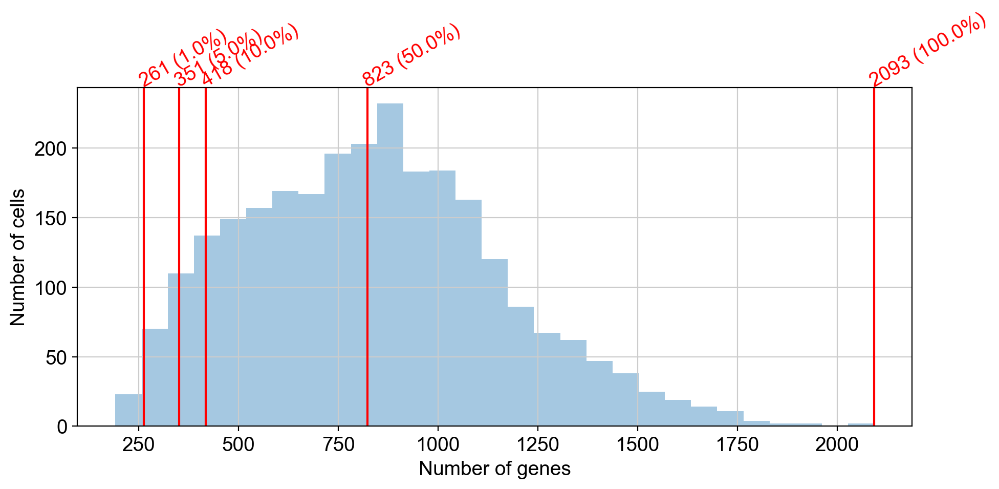

In [36]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
sns.distplot(nGenesDetectedPerCell, norm_hist=False, kde=False, bins='fd')
for i,x in enumerate(percentiles):
    fig.gca().axvline(x=x, ymin=0, ymax=1, color='red')
    ax.text(x=x, y=ax.get_ylim()[1], s=f'{int(x)} ({percentiles.index.values[i]*100}%)', color='red', rotation=30, size='medium', rotation_mode='anchor')
ax.set_xlabel('Number of genes')
ax.set_ylabel('Number of cells')
plt.tight_layout()

In [ ]:
%%time
!pyscenic aucell \
    {f_loom_path_scenic} \
    {REGULONS_DAT_FNAME} \
    --output {AUCELL_MTX_FNAME} \
    --num_workers 16

# if pyscenic.cli.pyscenic - ERROR - binary mode doesn't take an encoding argument, go to /home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/pyscenic/cli/utils.py, change all openfile(fname, xxx) to open(fname, xxx)

Wall time: 45.6 s



2022-04-28 00:10:22,281 - pyscenic.cli.pyscenic - INFO - Loading expression matrix.

2022-04-28 00:10:22,834 - pyscenic.cli.pyscenic - INFO - Loading gene signatures.

2022-04-28 00:10:22,841 - pyscenic.cli.pyscenic - INFO - Calculating cellular enrichment.

2022-04-28 00:10:58,911 - pyscenic.cli.pyscenic - INFO - Writing results to file.


In [37]:
auc_mtx = pd.read_csv(AUCELL_MTX_FNAME, index_col=0)
auc_mtx

,Arnt2,Atf1,Atf3,Atf4,Atf5,Atf6,Atf6b,Atoh1,Bcl3,Bmyc,...,Zfp442,Zfp580,Zfp64,Zfp729b,Zfp784,Zfp825,Zfp90,Zfp932,Zfp94,Zfp958
Cell,,,,,,,,,,,,,,,,,,,,,
AAACCCAAGTCGAAGC-1,0.027481,0.002987,0.054746,0.046881,0.011304,0.043839,0.000000,0.006342,0.010469,0.000000,...,0.000000,0.000000,0.018539,0.0,0.000000,0.028531,0.000000,0.055958,0.018859,0.036551
AAACCCACAGCGCGTT-1,0.048728,0.031265,0.068514,0.050224,0.023615,0.120938,0.000000,0.014904,0.000000,0.146565,...,0.000000,0.000000,0.000000,0.0,0.026999,0.009351,0.000000,0.031265,0.048316,0.049484
AAACCCATCGTTCATT-1,0.039059,0.000000,0.035195,0.028758,0.008998,0.030643,0.000000,0.014232,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.015935,0.000000,0.000000,0.010058,0.000000
AAACGAAGTACCTGTA-1,0.042706,0.008297,0.022765,0.023417,0.000000,0.000000,0.000000,0.004986,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.030630,0.072061,0.010488,0.000000,0.000000
AAACGAAGTAGATTAG-1,0.026251,0.000000,0.060300,0.039209,0.043105,0.119847,0.000000,0.015513,0.008833,0.060458,...,0.000000,0.000000,0.000000,0.0,0.001205,0.011260,0.000000,0.008364,0.051280,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGGTTTCCGCGATG-1,0.024427,0.000000,0.035919,0.029439,0.014293,0.020938,0.000000,0.009150,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.011164,0.000000,0.027481,0.001976,0.000000
TTTGGTTTCTGCTCTG-1,0.027354,0.000000,0.047381,0.038451,0.014553,0.127481,0.016460,0.032008,0.000000,0.084122,...,0.000000,0.000000,0.057252,0.0,0.113700,0.000000,0.000000,0.002390,0.000000,0.000000
TTTGTTGAGGGCCTCT-1,0.036132,0.000000,0.076584,0.059422,0.017509,0.042639,0.000000,0.010740,0.027590,0.000000,...,0.036423,0.000000,0.000000,0.0,0.000000,0.043034,0.000000,0.021839,0.008532,0.052357


In [40]:
# STEP 5 - Binarization of cellular regulon activity

In [ ]:
%%time
binary_mtx, thresholds = binarize(auc_mtx, num_workers=16)
binary_mtx.to_csv(BINARY_MTX_FNAME)
thresholds.to_frame().rename(columns={0:'threshold'}).to_csv(THR_FNAME)

# if AttributeError: module 'numpy' has no attribute 'float'., go to /home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/pyscenic/diptest.py, line 64 np.float(numt) + 1 change to float(numt) + 1.0. Go to /home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/pyscenic/rss.py, line 21 dtype=np.float change to dtype=np.float32

Wall time: 7min 6s


In [38]:
binary_mtx = pd.read_csv(BINARY_MTX_FNAME, index_col=0)
binary_mtx

,Arnt2,Atf1,Atf3,Atf4,Atf5,Atf6,Atf6b,Atoh1,Bcl3,Bmyc,...,Zfp442,Zfp580,Zfp64,Zfp729b,Zfp784,Zfp825,Zfp90,Zfp932,Zfp94,Zfp958
Cell,,,,,,,,,,,,,,,,,,,,,
AAACCCAAGTCGAAGC-1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,1
AAACCCACAGCGCGTT-1,0,1,0,0,0,1,0,0,0,1,...,0,0,0,0,0,0,0,1,1,1
AAACCCATCGTTCATT-1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
AAACGAAGTACCTGTA-1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
AAACGAAGTAGATTAG-1,0,0,0,0,1,1,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGGTTTCCGCGATG-1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
TTTGGTTTCTGCTCTG-1,0,0,0,0,0,1,0,0,0,1,...,0,0,1,0,1,0,0,0,0,0
TTTGTTGAGGGCCTCT-1,0,0,1,1,0,1,0,0,1,0,...,0,0,0,0,0,1,0,1,0,1


In [39]:
thresholds = pd.read_csv(THR_FNAME, index_col=0).threshold
thresholds

Arnt2     0.058435
Atf1      0.018364
Atf3      0.068706
Atf4      0.052468
Atf5      0.029683
            ...   
Zfp825    0.031308
Zfp90     0.017105
Zfp932    0.015459
Zfp94     0.028059
Zfp958    0.027892
Name: threshold, Length: 183, dtype: float64

C:\Users\Park_Lab\anaconda3\envs\KP_py38\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


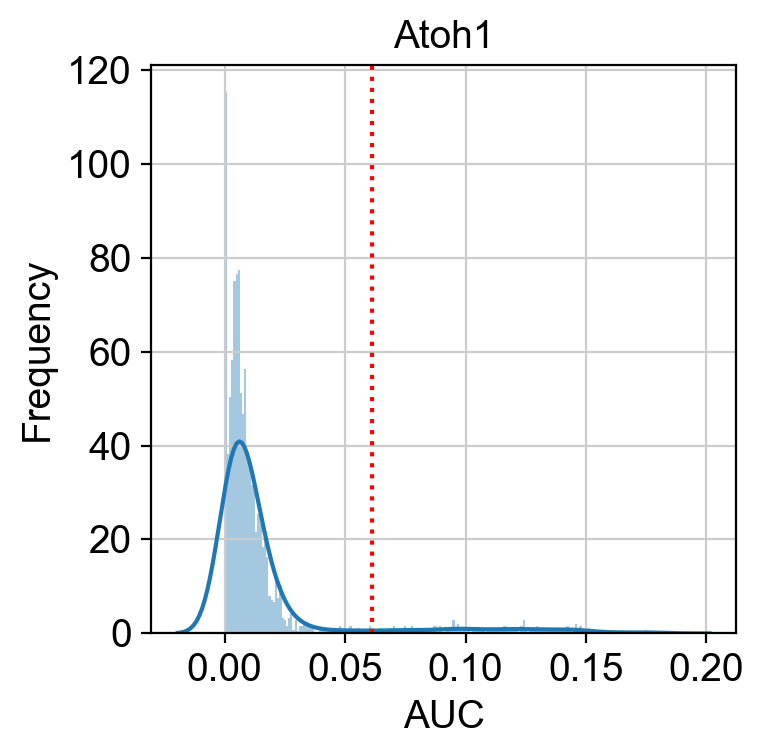

In [40]:
fig, ax = plt.subplots(1, 1)
plot_binarization(auc_mtx=auc_mtx, regulon_name='Atoh1', threshold=thresholds['Atoh1'])
ax.set_ylabel('Frequency')
plt.tight_layout()
savesvg('AUC_binarization_Atoh1.svg', fig)

In [41]:
fig, ((ax1, ax2, ax3, ax4, ax5), (ax6, ax7, ax8, ax9, ax10)) = plt.subplots(2, 5, figsize=(25, 10), dpi=300)
plot_binarization(auc_mtx, 'Atoh1', thresholds['Atoh1'], ax=ax1)
plot_binarization(auc_mtx, 'Tff3', thresholds['Tff3'], ax=ax2)
plot_binarization(auc_mtx, 'Spdef', thresholds['Spdef'], ax=ax3)
plot_binarization(auc_mtx, 'Foxa3', thresholds['Foxa3'], ax=ax4)
plot_binarization(auc_mtx, 'Creb3l4', thresholds['Creb3l4'], ax=ax5)
plot_binarization(auc_mtx, 'Atf6b', thresholds['Atf6b'], ax=ax6)
plot_binarization(auc_mtx, 'Mxd4', thresholds['Mxd4'], ax=ax7)
plot_binarization(auc_mtx, 'Nfkb2', thresholds['Nfkb2'], ax=ax8)
plot_binarization(auc_mtx, 'Xbp1', thresholds['Xbp1'], ax=ax9)
plot_binarization(auc_mtx, 'Atf6', thresholds['Atf6'], ax=ax10)
savesvg('binarization.svg', fig)

C:\Users\Park_Lab\anaconda3\envs\KP_py38\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
C:\Users\Park_Lab\anaconda3\envs\KP_py38\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
C:\Users\Park_Lab\anaconda3\envs\KP_py38\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with

In [42]:
# Create heatmap with binarized regulon activity

In [43]:
def palplot(pal, names, colors=None, size=1):
    n = len(pal)
    f, ax = plt.subplots(1, 1, figsize=(n * size, size))
    ax.imshow(np.arange(n).reshape(1, n),
              cmap=mpl.colors.ListedColormap(list(pal)),
              interpolation="nearest", aspect="auto")
    ax.set_xticks(np.arange(n) - 0.5)
    ax.set_yticks([-0.5, 0.5])
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    colors = n * ['k'] if colors is None else colors
    for idx, (name, color) in enumerate(zip(names, colors)):
        ax.text(0.0+idx, 0.0, name, color=color, horizontalalignment='center', verticalalignment='center')
    return f

In [44]:
N_COLORS = len(adata.obs['pca_leiden'].dtype.categories)
COLORS = [x for x in adata.uns['pca_leiden_colors']]
## if use system default colors, run COLORS = [color['color'] for color in mpl.rcParams["axes.prop_cycle"]]

In [45]:
pca_leiden_color_lut = dict(zip(adata.obs['pca_leiden'].dtype.categories, adata.uns['pca_leiden_colors']))
CellID_to_pca_leiden_lut = adata.obs['pca_leiden'].to_dict()
white_black_palette = sns.xkcd_palette(["white", "black"])

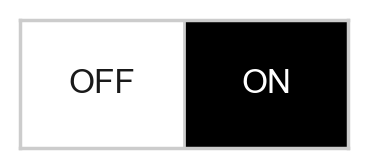

In [46]:
sns.set()
sns.set_style("whitegrid")
fig = palplot(white_black_palette, ['OFF', 'ON'], ['k', 'w'])
savesvg('on_off.svg', fig)

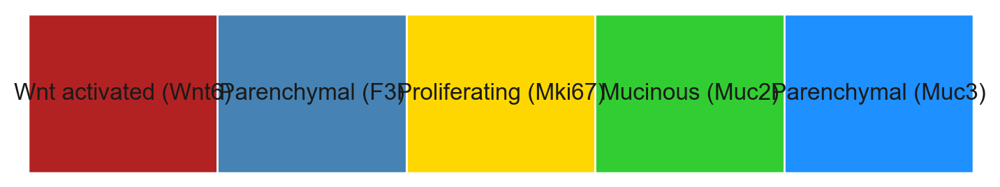

In [47]:
sns.set()
sns.set(font_scale=1)
fig = palplot(sns.color_palette(COLORS, n_colors=N_COLORS), adata.obs['pca_leiden'].dtype.categories, size=1.5)
savesvg('legend_pca_leiden_colors.svg', fig)

C:\Users\Park_Lab\anaconda3\envs\KP_py38\lib\site-packages\seaborn\matrix.py:654: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


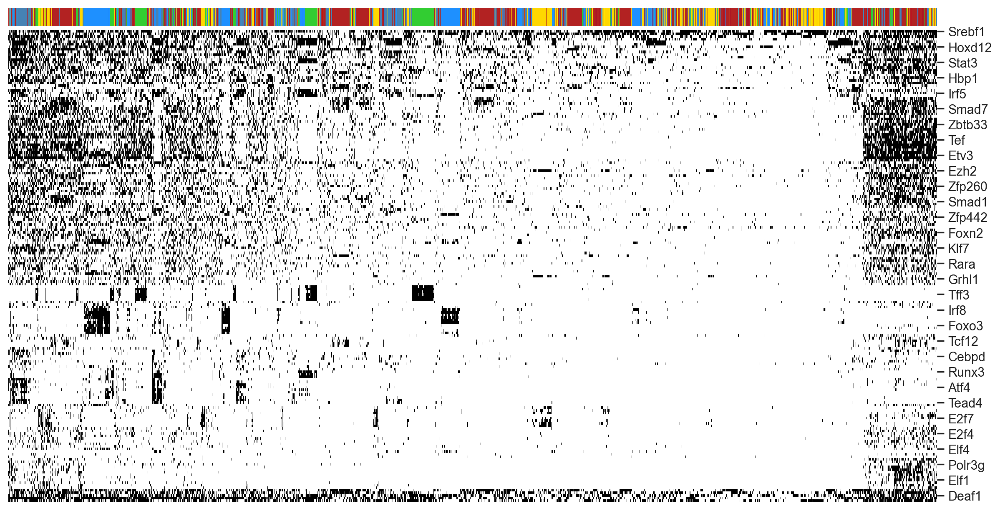

In [48]:
sns.set()
sns.set(font_scale=1)    # if do not reset later, this font size will affect all downstream plotting
sns.set_style("ticks", {"xtick.minor.size": 1, "ytick.minor.size": 0.1})
g = sns.clustermap(data=binary_mtx.T, figsize=(15,10),
                   col_colors=auc_mtx.index.map(CellID_to_pca_leiden_lut).map(pca_leiden_color_lut),
                   cmap=white_black_palette)
g.ax_heatmap.set_xticklabels([])
g.ax_heatmap.set_xticks([])
g.ax_heatmap.set_xlabel('')
g.ax_heatmap.set_ylabel('')
g.ax_col_colors.set_yticklabels([])
g.ax_col_colors.set_yticks([])
g.ax_row_dendrogram.set_visible(False)
g.ax_col_dendrogram.set_visible(False)
g.cax.set_visible(False)
g.fig.savefig(os.path.join(FIGURES_FOLDERNAME, 'clustermap - ACT_sub2.png'), format='png')

In [ ]:
# Save clustered binarized heatmap to Excel for further inspection
binary_mtx_clustered = binary_mtx.T.copy()
binary_mtx_clustered.rename(columns=adata.obs['pca_leiden'].to_dict(), inplace=True)
binary_mtx_clustered.to_csv(os.path.join(RESULTS_FOLDERNAME, 'Binarized regulon activity.csv'))

In [50]:
# Generate sequence logos
def fetch_logo(regulon, base_url = BASE_URL):
    for elem in regulon.context:
        if elem.endswith('.png'):
            return '<img src="{}{}" style="max-height:124px;"></img>'.format(base_url, elem)
    return ""

In [51]:
df_regulons = pd.DataFrame(data=[list(map(op.attrgetter('name'), regulons)),
                                 list(map(len, regulons)),
                                 list(map(fetch_logo, regulons))], index=['name', 'count', 'logo']).T

In [52]:
df_regulons.to_csv("C:/Users/hyjfo/Documents/ACT_sub2/motifs.csv")    # export the download addresses of motif logos

In [ ]:
MAX_COL_WIDTH = pd.get_option('display.max_colwidth')
pd.set_option('display.max_colwidth', None)
display(HTML(df_regulons.head().to_html(escape=False)))    # display head of all regulons
display(HTML(df_regulons.loc[df_regulons['name'].isin(['Atoh1', 'Tff3', 'Spdef', 'Foxa3', 'Creb3l4', 'Atf6b', 'Mxd4', 'Nfkb2', 'Xbp1', 'Atf6', 'Smad5', 'Ppara', 'Deaf1', 'Irf5', 'Ddit3', 'Spi1', 'Egr1', 'Pou5f1', 'Mlxip', 'Cebpb'])].to_html(escape=False)))    # display the wanted regulons
pd.set_option('display.max_colwidth', MAX_COL_WIDTH)

C:\Users\Park_Lab\AppData\Local\Temp/ipykernel_12148/1174137467.py:2: FutureWarning: Passing a negative integer is deprecated in version 1.0 and will not be supported in future version. Instead, use None to not limit the column width.
  pd.set_option('display.max_colwidth', -1)


,name,count,logo
0,Arnt2,36,
1,Atf1,23,
2,Atf3,721,
3,Atf4,648,
4,Atf5,47,


,name,count,logo
5,Atf6,14,
6,Atf6b,32,
7,Atoh1,143,
14,Cebpb,805,
17,Creb3l4,842,
20,Ddit3,38,
21,Deaf1,28,
29,Egr1,17,
42,Foxa3,13,
73,Irf5,49,


In [54]:
# STEP 6: Clustering of cells based on regulon activity

In [55]:
# We capture the non-linear projection based on PCA+umap for later storage in the loom file.
embedding_pca_umap = pd.DataFrame(adata.obsm['X_umap'], columns=[['_X', '_Y']], index=adata.obs_names)

In [56]:
adata

AnnData object with n_obs × n_vars = 2642 × 5000
    obs: 'predicted_doublets', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'pca_leiden'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'leiden', 'umap', 'leiden_colors', 'pca_leiden_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [57]:
# We add all metadata derived from SCENIC to the Scanpy AnnData object.
add_scenic_metadata(adata, auc_mtx, regulons)
adata.write_h5ad(ANNDATA_FNAME)

In [58]:
adata

AnnData object with n_obs × n_vars = 2642 × 5000
    obs: 'predicted_doublets', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'pca_leiden', 'Regulon(Arnt2)', 'Regulon(Atf1)', 'Regulon(Atf3)', 'Regulon(Atf4)', 'Regulon(Atf5)', 'Regulon(Atf6)', 'Regulon(Atf6b)', 'Regulon(Atoh1)', 'Regulon(Bcl3)', 'Regulon(Bmyc)', 'Regulon(Borcs8)', 'Regulon(Bptf)', 'Regulon(Brca1)', 'Regulon(Cdx2)', 'Regulon(Cebpb)', 'Regulon(Cebpd)', 'Regulon(Creb1)', 'Regulon(Creb3l4)', 'Regulon(Crebzf)', 'Regulon(Crem)', 'Regulon(Ddit3)', 'Regulon(Deaf1)', 'Regulon(E2f1)', 'Regulon(E2f2)', 'Regulon(E2f3)', 'Regulon(E2f4)', 'Regulon(E2f6)', 'Regulon(E2f7)', 'Regulon(E2f8)', 'Regulon(Egr1)', 'Regulon(Ehf)', 'Regulon(Elf1)', 'Regulon(Elf4)', 'Regulon(Elk4)', 'Regulon(Erf)', 'Regulon(Esrra)', 'Regulon(Etv3)', 'Regulon(Etv4)', 'Regulon(Ezh2)', 'Regulon(Fos)', 'Regulon(Fosb)', 'Regulon(Fosl1)', 'Regulo

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
running Leiden clustering
    finished: found 6 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:04)


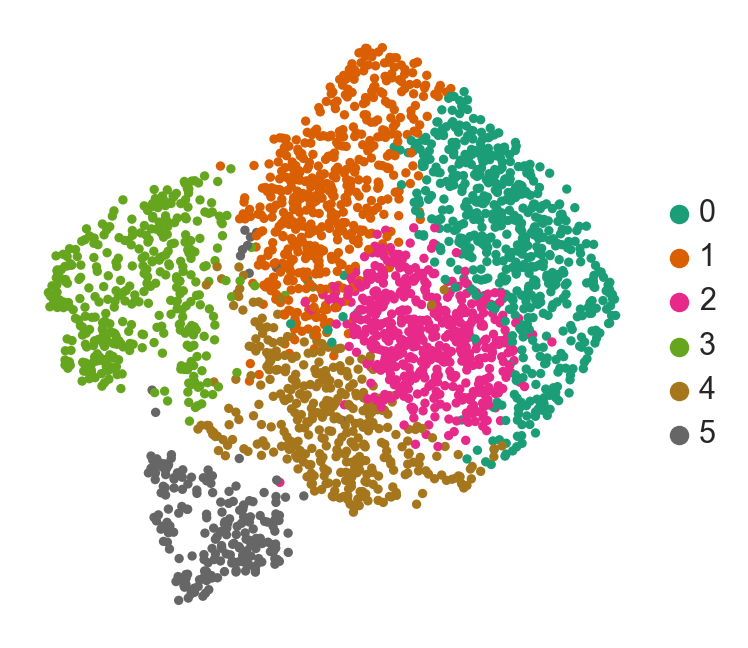

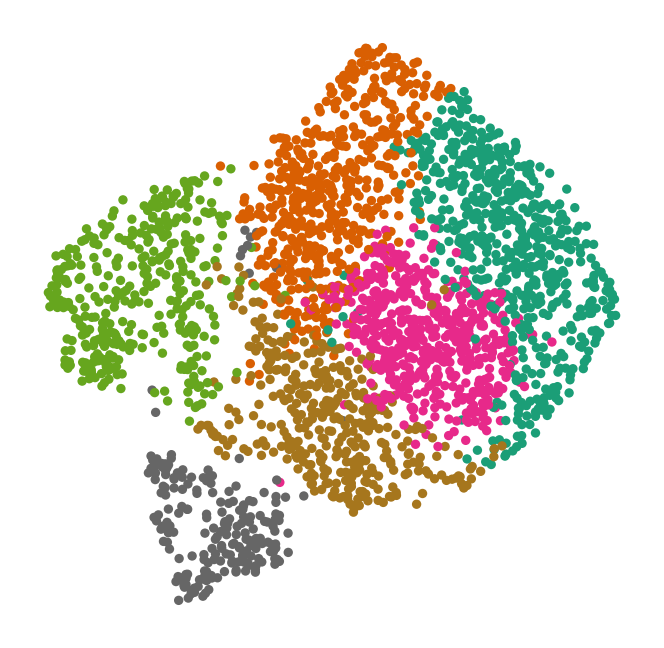

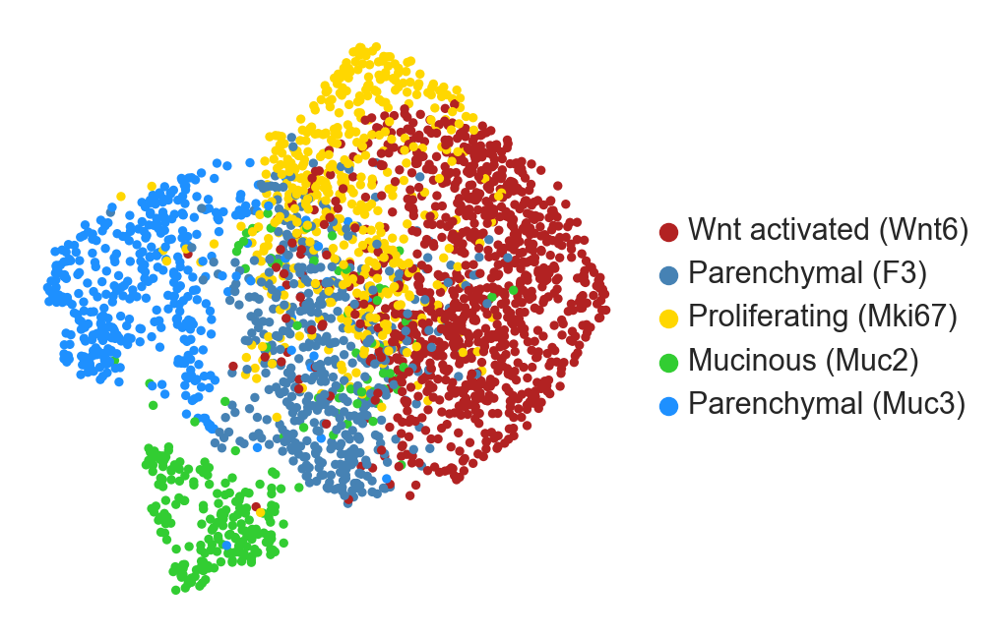

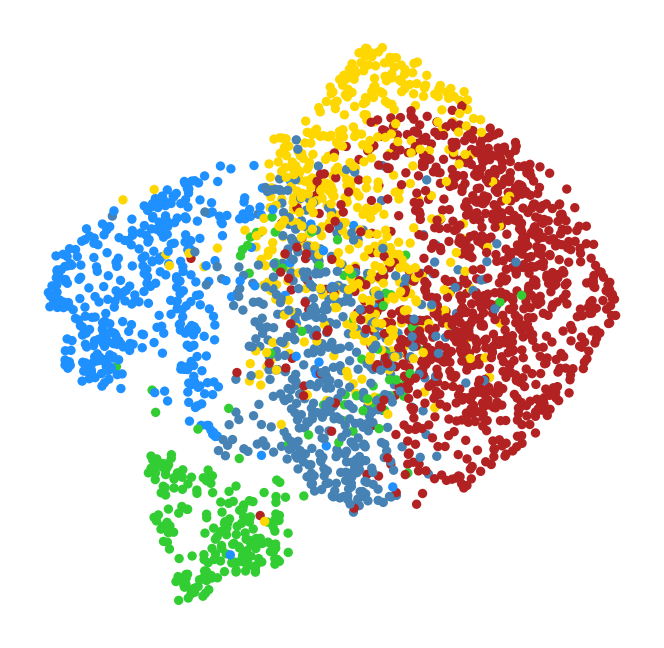

In [59]:
# AUCELL + umap PROJECTION
# We change the umap projection so that it relies on AUCell instead of PCA. Cells with similar regulons will cluster together.
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=50, use_rep='X_aucell', knn=True)
sc.tl.leiden(adata, resolution=0.4)    # this 'leiden' is calculated by aucell
sc.tl.umap(adata)
embedding_aucell_umap = pd.DataFrame(adata.obsm['X_umap'], columns=[['_X', '_Y']], index=adata.obs_names)
sc.pl.umap(adata, color=['leiden'], use_raw=False, frameon=False, legend_loc='right margin', title='', save='1.pdf', palette='Dark2')
sc.pl.umap(adata, color=['leiden'], use_raw=False, frameon=False, legend_loc='', title='', save='2.pdf')
sc.pl.umap(adata, color=['pca_leiden'], use_raw=False, frameon=False, legend_loc='right margin', title='', save='3.pdf')
sc.pl.umap(adata, color=['pca_leiden'], use_raw=False, frameon=False, legend_loc='', title='', save='4.pdf')

In [60]:
# CELL TYPE SPECIFIC REGULATORS - Z-SCORE
df_obs = adata.obs
signature_column_names = list(df_obs.select_dtypes('number').columns)
signature_column_names = list(filter(lambda s: s.startswith('Regulon('), signature_column_names))
df_scores = df_obs[signature_column_names + ['pca_leiden']]
df_results = ((df_scores.groupby(by='pca_leiden').mean() - df_obs[signature_column_names].mean())/ df_obs[signature_column_names].std()).stack().reset_index().rename(columns={'level_1': 'regulon', 0:'Z'})
df_results['Regulon'] = list(map(lambda s: s[8:-1], df_results.regulon))
df_results[(df_results.Z >= 1)].sort_values(['pca_leiden', 'Z'], ascending=False).to_csv('C:/Users/hyjfo/Documents/ACT_sub2/regulons.csv')

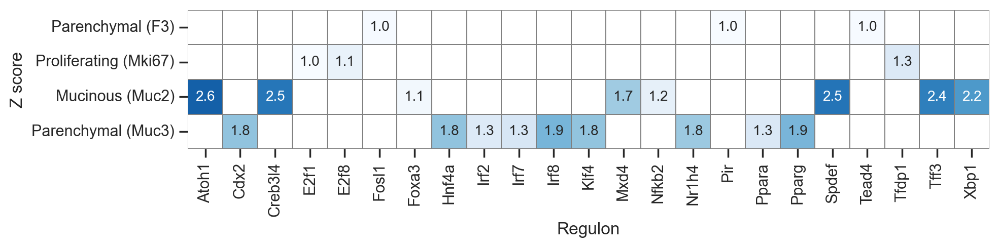

In [61]:
# show Z-score accross all clusters
df_heatmap = pd.pivot_table(data=df_results[df_results.Z >= 1].sort_values('Z', ascending=False),
                           index='pca_leiden', columns='Regulon', values='Z')
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.heatmap(df_heatmap, ax=ax, annot=True, fmt=".1f", linewidths=.7, cbar=False, square=True, linecolor='gray', 
            vmin=1, vmax=3, cmap="Blues", annot_kws={"size": 10})
ax.set_ylabel('Z score')
savesvg('heatmap_regulons_z_score.svg', fig)

In [62]:
# slice specific sub-cluster
Mucinous=df_results[df_results['pca_leiden']=='Mucinous (Muc2)']
Mucinous

,pca_leiden,regulon,Z,Regulon
549,Mucinous (Muc2),Regulon(Arnt2),-0.127135,Arnt2
550,Mucinous (Muc2),Regulon(Atf1),0.173168,Atf1
551,Mucinous (Muc2),Regulon(Atf3),-0.044665,Atf3
552,Mucinous (Muc2),Regulon(Atf4),0.618069,Atf4
553,Mucinous (Muc2),Regulon(Atf5),0.460199,Atf5
...,...,...,...,...
727,Mucinous (Muc2),Regulon(Zfp825),-0.529440,Zfp825
728,Mucinous (Muc2),Regulon(Zfp90),0.184181,Zfp90
729,Mucinous (Muc2),Regulon(Zfp932),0.023081,Zfp932
730,Mucinous (Muc2),Regulon(Zfp94),0.183335,Zfp94


C:\Users\Park_Lab\AppData\Local\Temp/ipykernel_12148/246009360.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_heatmap = pd.pivot_table(data=Mucinous[df_results.Z >= 2].sort_values('Z', ascending=False),


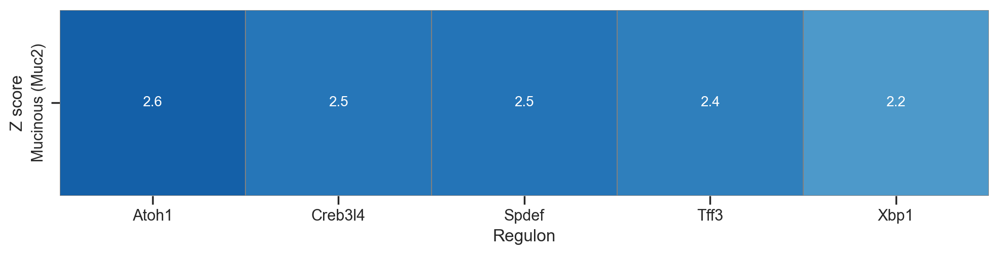

In [63]:
df_heatmap = pd.pivot_table(data=Mucinous[df_results.Z >= 2].sort_values('Z', ascending=False),
                           index='pca_leiden', columns='Regulon', values='Z')
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.heatmap(df_heatmap, ax=ax, annot=True, fmt=".1f", linewidths=.7, cbar=False, square=True, linecolor='gray', 
            vmin=1, vmax=3, cmap="Blues", annot_kws={"size": 10})
ax.set_ylabel('Z score')
savesvg('heatmap_regulons_z_score.svg', fig)

In [64]:
# CELL TYPE SPECIFIC REGULATORS - RSS
rss = regulon_specificity_scores(auc_mtx, adata.obs['pca_leiden'])
rss.T.to_csv('C:/Users/hyjfo/Documents/ACT_sub2/RSS.csv')

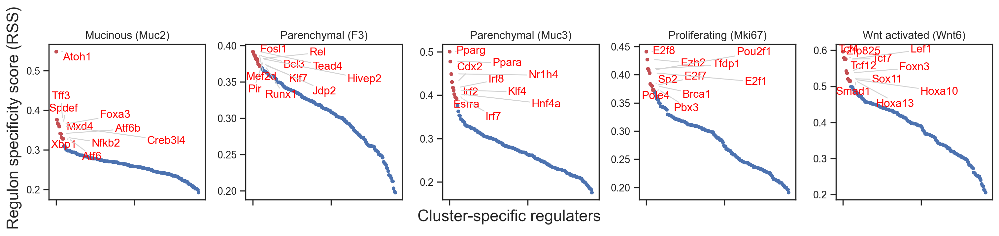

In [65]:
cats = sorted(list(set(adata.obs['pca_leiden'])))

fig = plt.figure(figsize=(15, 3))    # 3 is the total height of 1 row
for c,num in zip(cats, range(1,len(cats)+1)):
    x=rss.T[c]
    ax = fig.add_subplot(1,5,num)    # 1 means 1 row, 5 means 5 column
    plot_rss(rss, c, top_n=10, max_n=None, ax=ax)
    ax.set_ylim( x.min()-(x.max()-x.min())*0.05 , x.max()+(x.max()-x.min())*0.05)
    for t in ax.texts:
        t.set_fontsize(12)
    ax.set_ylabel('')
    ax.set_xlabel('')
    adjust_text(ax.texts, autoalign='xy', ha='right', va='bottom', arrowprops=dict(arrowstyle='-',color='lightgrey'), precision=0.001)
 
fig.text(0.5, 0.0, 'Cluster-specific regulaters', ha='center', va='center', size='x-large')
fig.text(0.00, 0.5, 'Regulon specificity score (RSS)', ha='center', va='center', rotation='vertical', size='x-large')
plt.tight_layout()
plt.rcParams.update({
    'figure.autolayout': True,
        'figure.titlesize': 'large',
        'axes.labelsize': 'medium',
        'axes.titlesize':'large',
        'xtick.labelsize':'medium',
        'ytick.labelsize':'medium'
        })
savesvg('plots_regulons_rss.svg', fig)
plt.show()

C:\Users\Park_Lab\anaconda3\envs\KP_py38\lib\site-packages\scanpy\plotting\_utils.py:288: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  pl.savefig(filename, dpi=dpi, bbox_inches='tight')
C:\Users\Park_Lab\anaconda3\envs\KP_py38\lib\site-packages\IPython\core\pylabtools.py:151: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


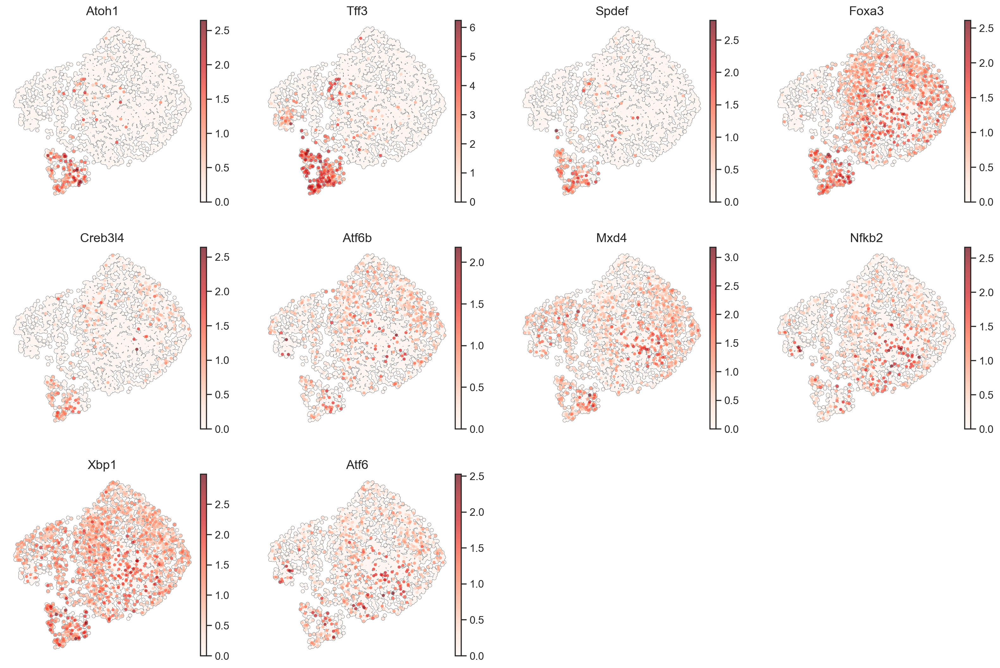

In [68]:
sc.pl.umap(adata, color=['Atoh1', 'Tff3', 'Spdef', 'Foxa3', 'Creb3l4', 'Atf6b', 'Mxd4', 'Nfkb2', 'Xbp1', 'Atf6'],
           legend_loc='right margin', frameon=False, vmin=0, add_outline=True, outline_width=(0.05,0.05), size=50, use_raw=True, cmap='Reds', save='5.pdf')

C:\Users\Park_Lab\anaconda3\envs\KP_py38\lib\site-packages\scanpy\plotting\_utils.py:288: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  pl.savefig(filename, dpi=dpi, bbox_inches='tight')
C:\Users\Park_Lab\anaconda3\envs\KP_py38\lib\site-packages\IPython\core\pylabtools.py:151: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


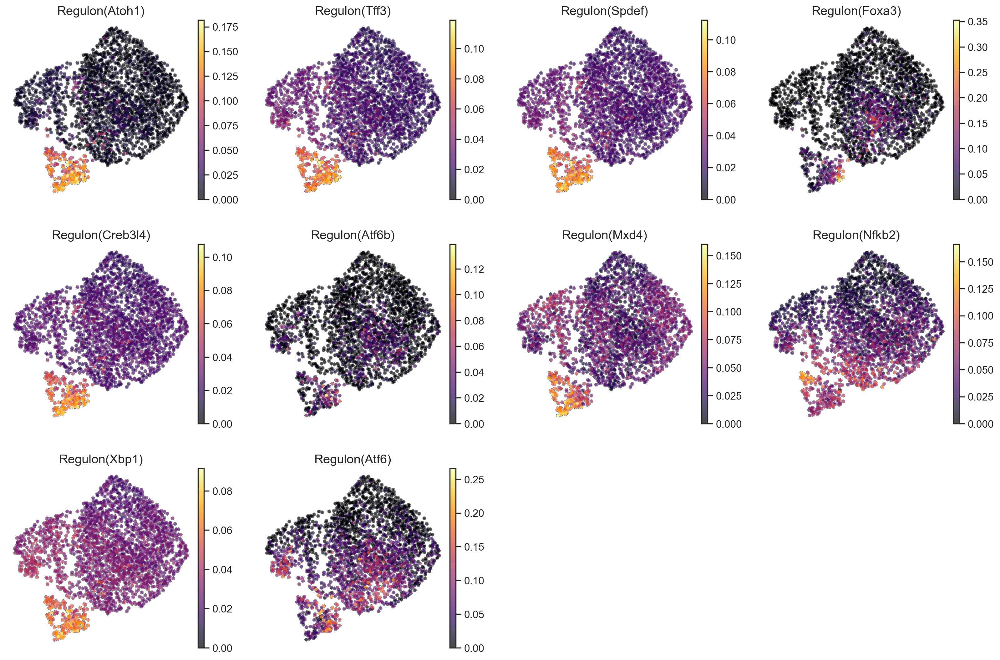

In [69]:
sc.pl.umap(adata, color=['Regulon(Atoh1)', 'Regulon(Tff3)', 'Regulon(Spdef)', 'Regulon(Foxa3)', 'Regulon(Creb3l4)', 'Regulon(Atf6b)', 'Regulon(Mxd4)', 'Regulon(Nfkb2)', 'Regulon(Xbp1)', 'Regulon(Atf6)'],
           legend_loc='right margin', frameon=False, vmin=0, add_outline=True, outline_width=(0.05,0.05), size=50, use_raw=True, cmap='inferno', save='6.pdf')

In [66]:
# AUCELL DISTRIBUTIONS
# We can also analyze the distribution of AUCell values via the plots in the scanpy package.
df_results.sort_values('Z', ascending=False).groupby(by='pca_leiden').head(5)

,pca_leiden,regulon,Z,Regulon
556,Mucinous (Muc2),Regulon(Atoh1),2.625436,Atoh1
691,Mucinous (Muc2),Regulon(Spdef),2.474730,Spdef
566,Mucinous (Muc2),Regulon(Creb3l4),2.460037,Creb3l4
710,Mucinous (Muc2),Regulon(Tff3),2.397685,Tff3
717,Mucinous (Muc2),Regulon(Xbp1),2.180656,Xbp1
807,Parenchymal (Muc3),Regulon(Irf8),1.944783,Irf8
848,Parenchymal (Muc3),Regulon(Pparg),1.935692,Pparg
745,Parenchymal (Muc3),Regulon(Cdx2),1.818393,Cdx2
793,Parenchymal (Muc3),Regulon(Hnf4a),1.816551,Hnf4a
816,Parenchymal (Muc3),Regulon(Klf4),1.809519,Klf4


         Falling back to preprocessing with `sc.pp.pca` and default params.
computing PCA
    with n_comps=50
    finished (0:00:00)
Storing dendrogram info using `.uns['dendrogram_pca_leiden']`


C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\scanpy\plotting\_utils.py:288: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  pl.savefig(filename, dpi=dpi, bbox_inches='tight')
C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\scanpy\plotting\_utils.py:288: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  pl.savefig(filename, dpi=dpi, bbox_inches='tight')
C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\IPython\core\pylabtools.py:151: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


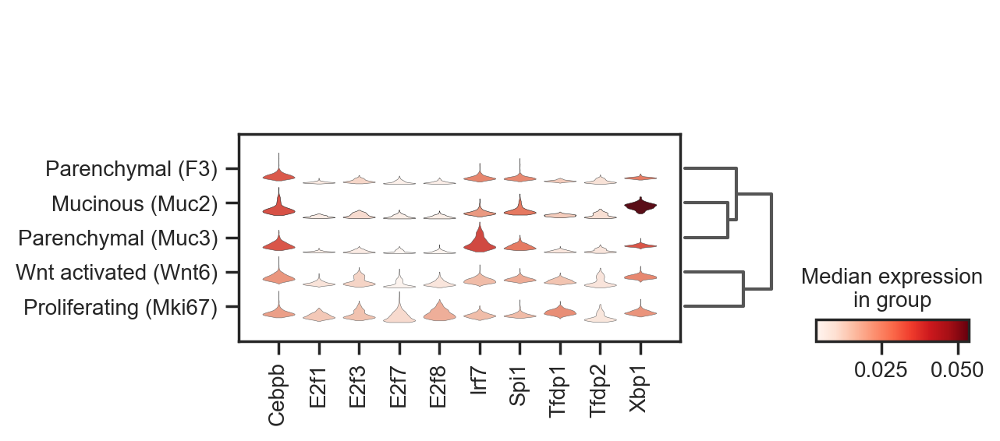

In [67]:
aucell_adata = sc.AnnData(X=auc_mtx.sort_index())
aucell_adata.obs = df_obs
names = list(map(op.attrgetter('name'), filter(lambda r: r.score > 8.0, regulons)))
sc.pl.stacked_violin(aucell_adata, names, groupby='pca_leiden', use_raw=False, dendrogram=True, save='7.pdf', cmap='Reds')

In [85]:
# STEP 7: Export to SCope

In [68]:
export2loom(ex_mtx=adata.to_df(), regulons=regulons, out_fname=LOOM_FNAME,
            cell_annotations=adata.obs['pca_leiden'].to_dict(), tree_structure=(),
            title='{}_{}'.format(TCGA_CODE, DATASET_ID), nomenclature="mm10", num_workers=16,
            embeddings=OrderedDict([('AUCell + umap', embedding_aucell_umap), ('PCA + umap', embedding_pca_umap)]),
            auc_mtx = auc_mtx, auc_thresholds=thresholds,
            compress=True)

Regulon name does not seem to be compatible with SCOPE. It should include a space to allow selection of the TF. 
Please run: 
 regulons = [r.rename(r.name.replace('(+)',' ('+str(len(r))+'g)')) for r in regulons] 
or:
 regulons = [r.rename(r.name.replace('(',' (')) for r in regulons]


In [87]:
# Step 8: Cytoscape-iRegulon exploration of modules

In [69]:
adjacencies = pd.read_csv(ADJACENCIES_FNAME, index_col=False, sep='\t')
adjacencies

,TF,target,importance
0,Ckmt1,Lgals4,1.391939e+02
1,Anxa1,Anxa2,1.241420e+02
2,Ckmt1,2200002D01Rik,1.150750e+02
3,Ckmt1,Mgst3,1.146697e+02
4,Pkm,Gapdh,1.125123e+02
...,...,...,...
4947529,Nr2f6,Defa5,9.354507e-20
4947530,Sp3,Clca1,8.251099e-20
4947531,Gtf2h3,Defa36,5.053714e-20
4947532,Timeless,Apoe,4.637854e-20


In [70]:
# Create the modules
from pyscenic.utils import modules_from_adjacencies
lf = lp.connect(f_loom_path_scenic, mode='r', validate=False)
exprMat = pd.DataFrame(lf[:,:], index=lf.ra.Gene, columns=lf.ca.CellID).T
modules = list(modules_from_adjacencies(adjacencies, exprMat))
lf.close()


2022-10-23 20:48:03,337 - pyscenic.utils - INFO - Calculating Pearson correlations.

2022-10-23 20:48:06,422 - pyscenic.utils - WARNING - Note on correlation calculation: the default behaviour for calculating the correlations has changed after pySCENIC verion 0.9.16. Previously, the default was to calculate the correlation between a TF and target gene using only cells with non-zero expression values (mask_dropouts=True). The current default is now to use all cells to match the behavior of the R verision of SCENIC. The original settings can be retained by setting 'rho_mask_dropouts=True' in the modules_from_adjacencies function, or '--mask_dropouts' from the CLI.
	Dropout masking is currently set to [False].

2022-10-23 20:49:36,101 - pyscenic.utils - INFO - Creating modules.


In [71]:
# create a dictionary of regulons for converting the index from string to values:
lf2 = lp.connect(LOOM_FNAME, mode='r', validate=False)
regulons_dict = {}
for i,r in pd.DataFrame(lf2.ra.Regulons, index=lf2.ra.Gene).iteritems():
    regulons_dict[i] =  list(r[r==1].index.values)
lf2.close()

In [72]:
# pick out modules for Atoh1
tf = 'Spdef'
tf_mods = [ x for x in modules if x.transcription_factor==tf ]

for i,mod in enumerate( tf_mods ):
    print( f'{tf} module {str(i)}: {len(mod.genes)} genes' )
print( f'{tf} regulon: {len(regulons_dict[tf])} genes' )

Spdef module 0: 1532 genes
Spdef module 1: 950 genes
Spdef module 2: 51 genes
Spdef module 3: 293 genes
Spdef module 4: 436 genes
Spdef module 5: 1119 genes
Spdef regulon: 314 genes


In [73]:
# write these modules, and the regulon to files
for i,mod in enumerate( tf_mods ):
    with open( tf+'_module_'+str(i)+'.txt', 'w') as f:
        for item in mod.genes:
            f.write("%s\n" % item)
            
with open( tf+'_regulon.txt', 'w') as f:
    for item in regulons_dict[tf]:
        f.write("%s\n" % item)

In [ ]:
# Step 9: Cytoscape-iRegulon